# Unit06_UMAP | 均勻流形逼近與投影：大規模製程數據的降維與視覺化

本 Notebook 以程式生成的模擬反應器操作數據（5000 筆、30 個製程變數、4 種操作模式），建立 UMAP (Uniform Manifold Approximation and Projection) 模型來進行高維數據的降維與視覺化，並與 PCA 和 t-SNE 進行比較。

## 目標
- 理解 UMAP 的核心原理與優勢
- 學會使用 umap-learn 套件進行降維
- 掌握 UMAP 的關鍵超參數調整
- 學會評估降維結果的品質
- 比較 UMAP、t-SNE 與 PCA 的效果
- 應用 UMAP 於大規模製程數據視覺化

資料背景：程式生成的反應器多變數製程模擬數據（溫度、壓力、流量等，含 4 種操作模式）


---
### 0. 環境設定


In [1]:
from pathlib import Path
import os

# ========================================
# 路徑設定 (兼容 Colab 與 Local)
# ========================================
UNIT_OUTPUT_DIR = 'P2_Unit06_UMAP'

try:
    from google.colab import drive
    IN_COLAB = True
    print("✓ 偵測到 Colab 環境，準備掛載 Google Drive...")
    drive.mount('/content/drive', force_remount=True)
except ImportError:
    IN_COLAB = False
    print("✓ 偵測到 Local 環境")

try:
    shortcut_path = '/content/ChemE-3590'
    os.remove(shortcut_path)
except (FileNotFoundError, OSError):
    pass

if IN_COLAB:
    source_path = Path('/content/drive/My Drive/Colab Notebooks/ChemE-3590')
    os.symlink(source_path, shortcut_path)
    shortcut_path = Path(shortcut_path)
    if source_path.exists():
        NOTEBOOK_DIR = shortcut_path / 'Part_2' / 'Unit06'
        OUTPUT_DIR = NOTEBOOK_DIR / 'outputs' / UNIT_OUTPUT_DIR
        MODEL_DIR = OUTPUT_DIR / 'models'
        FIG_DIR = OUTPUT_DIR / 'figs'
    else:
        print("⚠️ 找不到路徑雲端ChemE-3590路徑，請確認自己的雲端資料夾是否正確")
else:
    NOTEBOOK_DIR = Path.cwd()
    OUTPUT_DIR = NOTEBOOK_DIR / 'outputs' / UNIT_OUTPUT_DIR
    MODEL_DIR = OUTPUT_DIR / 'models'
    FIG_DIR = OUTPUT_DIR / 'figs'

# 建立必要資料夾（本 Notebook 使用程式生成的數據，不需要 data 目錄）
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f"\n📂 工作目錄: {NOTEBOOK_DIR}")
print(f"📂 輸出目錄: {OUTPUT_DIR}")
print(f"📂 模型目錄: {MODEL_DIR}")
print(f"📂 圖片目錄: {FIG_DIR}")


✓ 偵測到 Local 環境

📂 工作目錄: d:\MyGit\ChemE-3590\Part_2\Unit06
📂 輸出目錄: d:\MyGit\ChemE-3590\Part_2\Unit06\outputs\P2_Unit06_UMAP
📂 模型目錄: d:\MyGit\ChemE-3590\Part_2\Unit06\outputs\P2_Unit06_UMAP\models
📂 圖片目錄: d:\MyGit\ChemE-3590\Part_2\Unit06\outputs\P2_Unit06_UMAP\figs


---
### 載入套件


In [2]:
# 載入相關套件
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score
import umap
import warnings
import time

# 設定隨機種子以確保結果可重現
SEED = 42
np.random.seed(SEED)
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

# 繪圖樣式設定
plt.rcParams.update({
    'figure.dpi': 100,
    'savefig.dpi': 300,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.unicode_minus': False,
})

print("✓ 套件載入完成")
print(f"  numpy      版本: {np.__version__}")
print(f"  scipy      版本: {scipy.__version__}")
print(f"  matplotlib 版本: {matplotlib.__version__}")
print(f"  umap-learn 版本: {umap.__version__}")


✓ 套件載入完成
  numpy      版本: 1.26.4
  scipy      版本: 1.15.2
  matplotlib 版本: 3.10.8
  umap-learn 版本: 0.5.11


---
## 1. 生成模擬反應器操作數據


In [3]:
def generate_reactor_operation_data(n_samples=5000, n_features=30, n_modes=4, noise_level=0.1):
    """
    生成模擬反應器操作數據（4種操作模式）
    
    Parameters:
    -----------
    n_samples : int
        樣本數量
    n_features : int
        特徵數量（製程變數）
    n_modes : int
        操作模式數量
    noise_level : float
        噪音水平
    
    Returns:
    --------
    X : ndarray, shape (n_samples, n_features)
        特徵矩陣
    y : ndarray, shape (n_samples,)
        操作模式標籤
    feature_names : list
        特徵名稱
    """
    np.random.seed(42)
    
    # 定義 4 種操作模式的中心點（在高維空間中）
    centers = np.array([
        [1.0, 0.5, 0.3] + [0.2] * (n_features - 3),   # 模式 0: 低溫低壓
        [2.0, 1.5, 0.8] + [0.5] * (n_features - 3),   # 模式 1: 中溫中壓
        [3.0, 2.5, 1.5] + [0.8] * (n_features - 3),   # 模式 2: 高溫高壓
        [1.5, 2.0, 1.0] + [0.6] * (n_features - 3)    # 模式 3: 混合模式
    ])
    
    # 生成數據
    samples_per_mode = n_samples // n_modes
    X = []
    y = []
    
    for mode_idx in range(n_modes):
        # 生成該模式的樣本
        mode_samples = np.random.randn(samples_per_mode, n_features) * noise_level + centers[mode_idx]
        
        # 添加模式特定的相關性
        if mode_idx == 0:  # 低溫低壓：第1-3個變數高度相關
            mode_samples[:, 1] = 0.9 * mode_samples[:, 0] + np.random.randn(samples_per_mode) * 0.1
            mode_samples[:, 2] = 0.8 * mode_samples[:, 0] + np.random.randn(samples_per_mode) * 0.1
        elif mode_idx == 1:  # 中溫中壓：第4-6個變數高度相關
            mode_samples[:, 4] = 0.9 * mode_samples[:, 3] + np.random.randn(samples_per_mode) * 0.1
            mode_samples[:, 5] = 0.8 * mode_samples[:, 3] + np.random.randn(samples_per_mode) * 0.1
        elif mode_idx == 2:  # 高溫高壓：引入非線性關係
            mode_samples[:, 7] = mode_samples[:, 6] ** 2 + np.random.randn(samples_per_mode) * 0.1
            mode_samples[:, 8] = np.sin(mode_samples[:, 6]) + np.random.randn(samples_per_mode) * 0.1
        else:  # 混合模式：多個變數交互作用
            mode_samples[:, 10] = (mode_samples[:, 9] * mode_samples[:, 11]) + np.random.randn(samples_per_mode) * 0.1
        
        X.append(mode_samples)
        y.extend([mode_idx] * samples_per_mode)
    
    X = np.vstack(X)
    y = np.array(y)
    
    # 隨機打亂數據
    shuffle_idx = np.random.permutation(len(X))
    X = X[shuffle_idx]
    y = y[shuffle_idx]
    
    # 生成特徵名稱
    feature_names = [
        'Temperature_1', 'Pressure_1', 'Flow_Rate_1',
        'Temperature_2', 'Pressure_2', 'Flow_Rate_2',
        'Concentration_A', 'Concentration_B', 'Concentration_C',
        'pH', 'Viscosity', 'Density'
    ] + [f'Sensor_{i}' for i in range(13, n_features + 1)]
    
    return X, y, feature_names

# 生成數據
X, y, feature_names = generate_reactor_operation_data(n_samples=5000, n_features=30, n_modes=4)

print(f"✓ 數據生成完成")
print(f"  - 樣本數量: {X.shape[0]}")
print(f"  - 特徵數量: {X.shape[1]}")
print(f"  - 操作模式數量: {len(np.unique(y))}")
print(f"\n操作模式分布:")
for mode in np.unique(y):
    count = np.sum(y == mode)
    print(f"  模式 {mode}: {count} 樣本 ({count/len(y)*100:.1f}%)")


✓ 數據生成完成
  - 樣本數量: 5000
  - 特徵數量: 30
  - 操作模式數量: 4

操作模式分布:
  模式 0: 1250 樣本 (25.0%)
  模式 1: 1250 樣本 (25.0%)
  模式 2: 1250 樣本 (25.0%)
  模式 3: 1250 樣本 (25.0%)


---
## 2. 數據前處理


In [4]:
# 數據標準化 (UMAP 建議標準化)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("✓ 數據標準化完成")
print(f"  - 標準化後數據形狀: {X_scaled.shape}")
print(f"  - 標準化後均值: {X_scaled.mean(axis=0)[:5]} ... (顯示前5個)")
print(f"  - 標準化後標準差: {X_scaled.std(axis=0)[:5]} ... (顯示前5個)")


✓ 數據標準化完成
  - 標準化後數據形狀: (5000, 30)
  - 標準化後均值: [-1.88412619e-15 -8.57525162e-15 -5.51910809e-15 -5.50583190e-15
 -2.29858355e-15] ... (顯示前5個)
  - 標準化後標準差: [1. 1. 1. 1. 1.] ... (顯示前5個)


---
## 3. UMAP 降維

### 3.1 基本 UMAP 模型

In [5]:
# 建立 UMAP 模型
start_time = time.time()

reducer = umap.UMAP(
    n_neighbors=30,      # 鄰居數（控制局部-全局平衡）
    n_components=2,      # 降至 2 維
    min_dist=0.1,        # 最小距離
    metric='euclidean',  # 距離度量
    random_state=42,     # 隨機種子
    n_epochs=200,        # 迭代次數
    verbose=True         # 顯示訓練進度
)

# 訓練並轉換數據
X_umap = reducer.fit_transform(X_scaled)

elapsed_time = time.time() - start_time

print(f"\n✓ UMAP 降維完成")
print(f"  - 降維後形狀: {X_umap.shape}")
print(f"  - 訓練時間: {elapsed_time:.2f} 秒（首次執行含 numba JIT 編譯時間，後續同參數訓練會明顯較快）")


UMAP(n_epochs=200, n_jobs=1, n_neighbors=30, random_state=42, verbose=True)
Thu Oct 29 21:17:51 2026 Construct fuzzy simplicial set
Thu Oct 29 21:17:51 2026 Finding Nearest Neighbors
Thu Oct 29 21:17:51 2026 Building RP forest with 9 trees
Thu Oct 29 21:17:58 2026 NN descent for 12 iterations
	 1  /  12
	 2  /  12
	 3  /  12
	Stopping threshold met -- exiting after 3 iterations
Thu Oct 29 21:18:11 2026 Finished Nearest Neighbor Search
Thu Oct 29 21:18:14 2026 Construct embedding
	completed  0  /  200 epochs
	completed  20  /  200 epochs
	completed  40  /  200 epochs
	completed  60  /  200 epochs
	completed  80  /  200 epochs
	completed  100  /  200 epochs
	completed  120  /  200 epochs
	completed  140  /  200 epochs
	completed  160  /  200 epochs
	completed  180  /  200 epochs
Thu Oct 29 21:18:20 2026 Finished embedding

✓ UMAP 降維完成
  - 降維後形狀: (5000, 2)
  - 訓練時間: 29.45 秒（首次執行含 numba JIT 編譯時間，後續同參數訓練會明顯較快）


### 3.2 視覺化 UMAP 結果

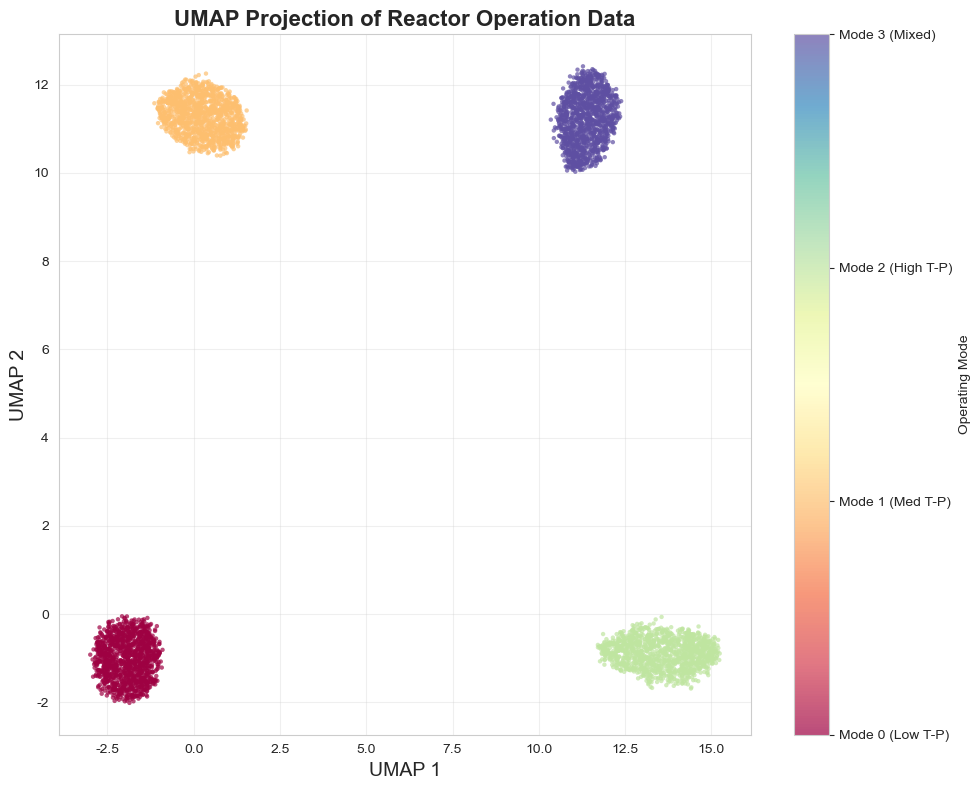

✓ 圖片已儲存至: d:\MyGit\ChemE-3590\Part_2\Unit06\outputs\P2_Unit06_UMAP\figs\umap_basic_projection.png


In [6]:
# 繪製 UMAP 結果
fig, ax = plt.subplots(figsize=(10, 8))

scatter = ax.scatter(X_umap[:, 0], X_umap[:, 1], 
                    c=y, cmap='Spectral', s=10, alpha=0.7, edgecolors='none')

cbar = plt.colorbar(scatter, ax=ax, label='Operating Mode')
cbar.set_ticks([0, 1, 2, 3])
cbar.set_ticklabels(['Mode 0 (Low T-P)', 'Mode 1 (Med T-P)', 'Mode 2 (High T-P)', 'Mode 3 (Mixed)'])

ax.set_title('UMAP Projection of Reactor Operation Data', fontsize=16, fontweight='bold')
ax.set_xlabel('UMAP 1', fontsize=14)
ax.set_ylabel('UMAP 2', fontsize=14)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / 'umap_basic_projection.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ 圖片已儲存至:", FIG_DIR / 'umap_basic_projection.png')


---
## 4. 超參數探索

### 4.1 探索 n_neighbors 的影響

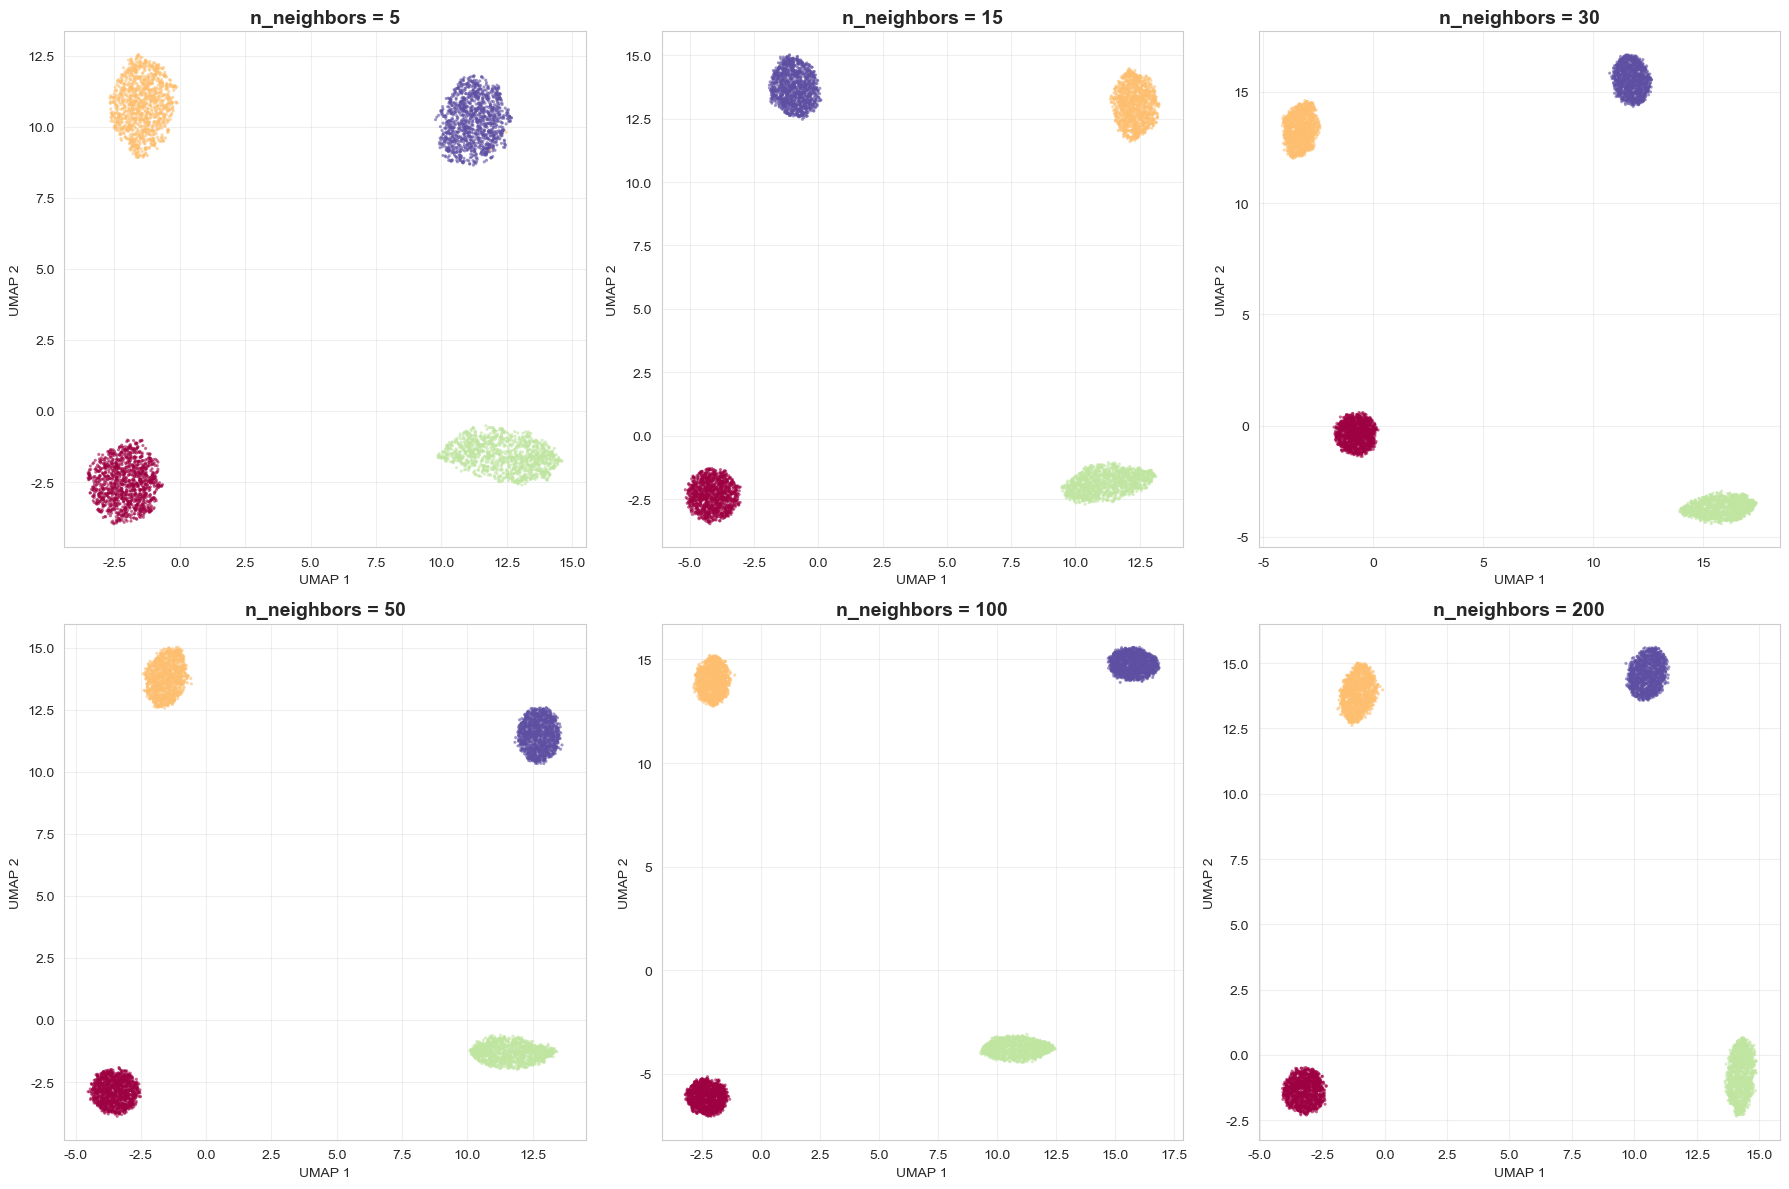

✓ 圖片已儲存至: d:\MyGit\ChemE-3590\Part_2\Unit06\outputs\P2_Unit06_UMAP\figs\umap_n_neighbors_exploration.png

觀察重點:
  - 一般趨勢: 小 n_neighbors 強調局部結構（易碎片化），大 n_neighbors 保留更多全局結構（易融合）
  - 本範例: 4 個操作模式分離良好，所有 n_neighbors 值都維持 4 個清楚的群集，差異主要在群集形狀與緊密度
  - 注意: 群集在圖中的排列位置與群集間距離會隨設定而變，不具物理意義


In [7]:
# 探索不同 n_neighbors 值的影響
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
n_neighbors_list = [5, 15, 30, 50, 100, 200]

for idx, n_neighbors in enumerate(n_neighbors_list):
    ax = axes[idx // 3, idx % 3]
    
    # 建立並訓練 UMAP
    reducer_temp = umap.UMAP(
        n_neighbors=n_neighbors, 
        n_components=2, 
        min_dist=0.1, 
        random_state=42,
        verbose=False
    )
    X_umap_temp = reducer_temp.fit_transform(X_scaled)
    
    # 繪圖
    scatter = ax.scatter(X_umap_temp[:, 0], X_umap_temp[:, 1], 
                        c=y, cmap='Spectral', s=5, alpha=0.6, edgecolors='none')
    ax.set_title(f'n_neighbors = {n_neighbors}', fontsize=14, fontweight='bold')
    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / 'umap_n_neighbors_exploration.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ 圖片已儲存至:", FIG_DIR / 'umap_n_neighbors_exploration.png')
print("\n觀察重點:")
print("  - 一般趨勢: 小 n_neighbors 強調局部結構（易碎片化），大 n_neighbors 保留更多全局結構（易融合）")
print("  - 本範例: 4 個操作模式分離良好，所有 n_neighbors 值都維持 4 個清楚的群集，差異主要在群集形狀與緊密度")
print("  - 注意: 群集在圖中的排列位置與群集間距離會隨設定而變，不具物理意義")


### 4.2 探索 min_dist 的影響

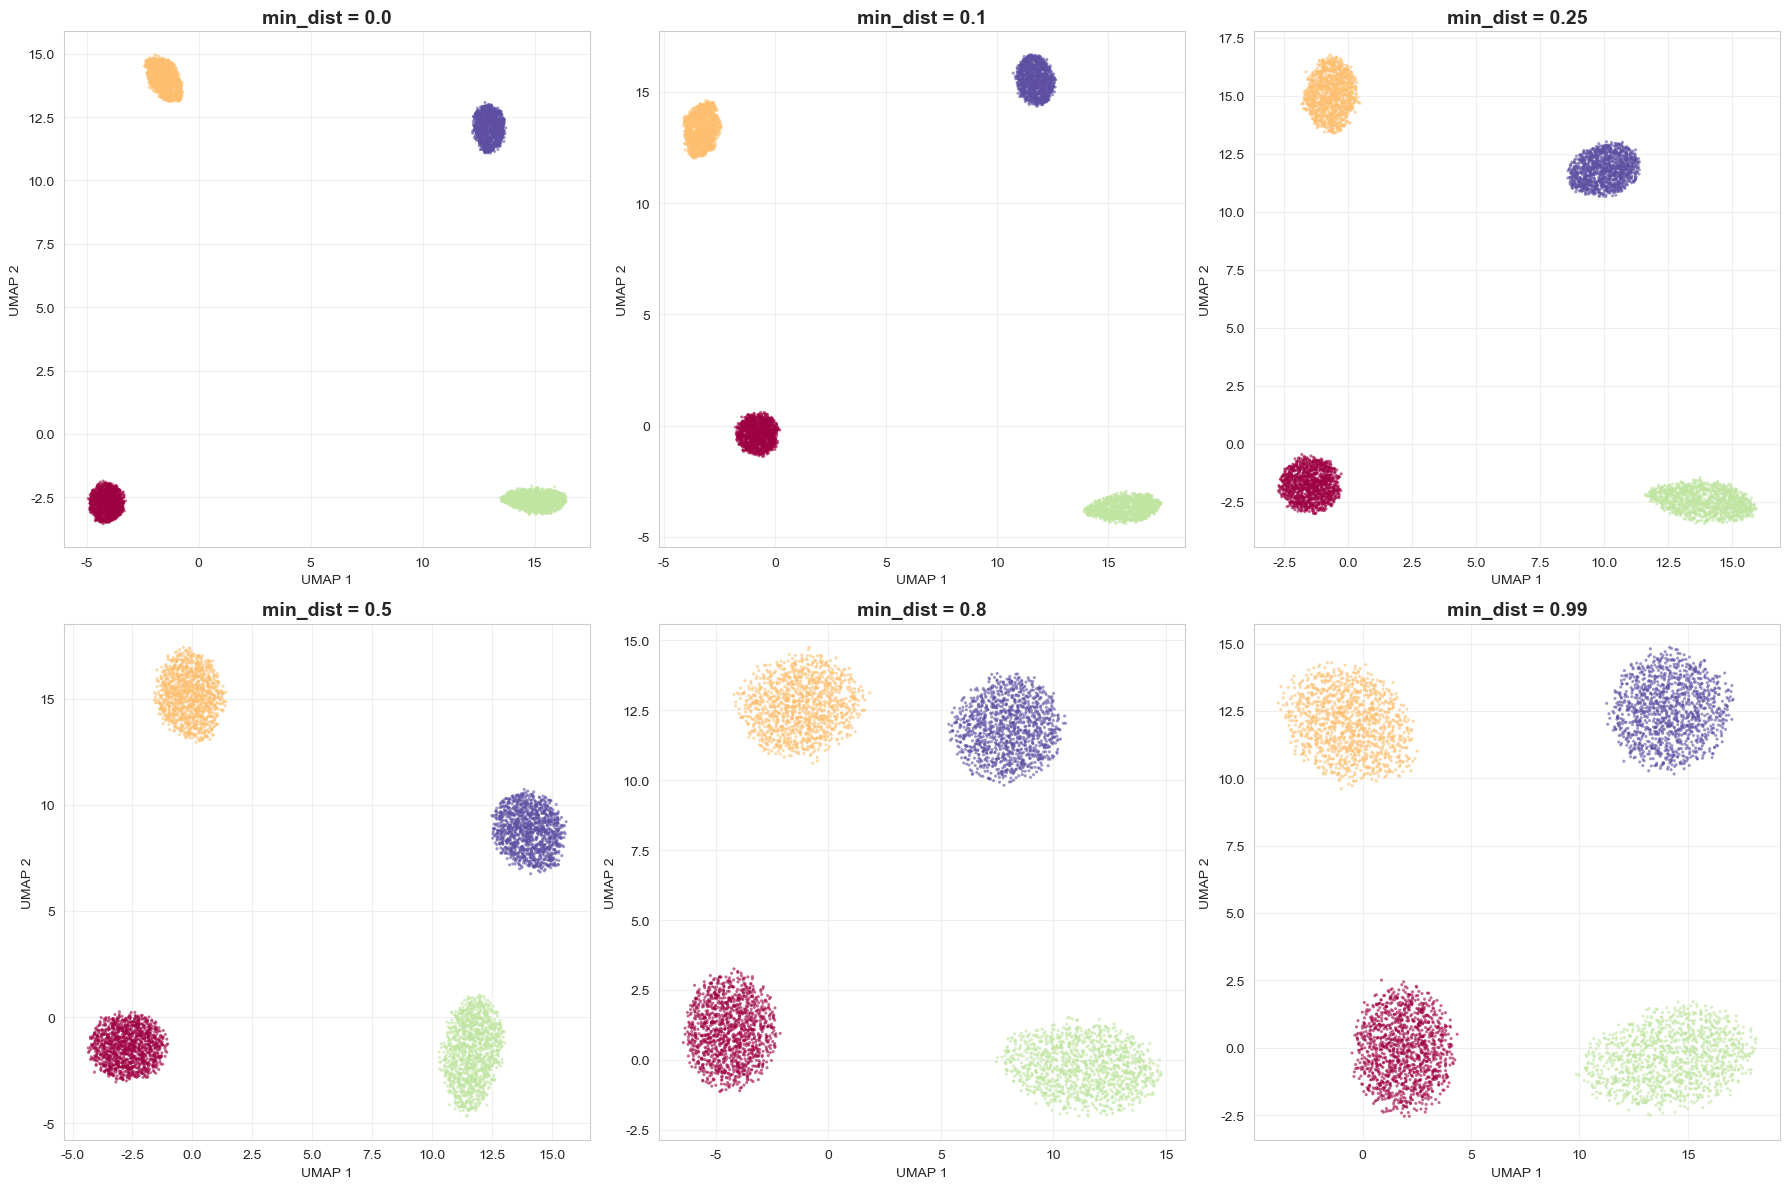

✓ 圖片已儲存至: d:\MyGit\ChemE-3590\Part_2\Unit06\outputs\P2_Unit06_UMAP\figs\umap_min_dist_exploration.png

觀察重點:
  - 小 min_dist (0.0-0.1): 點聚集更緊，群集邊界更清晰
  - 大 min_dist (0.5-0.99): 點分布更均勻，結構更鬆散


In [8]:
# 探索不同 min_dist 值的影響
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
min_dist_list = [0.0, 0.1, 0.25, 0.5, 0.8, 0.99]

for idx, min_dist in enumerate(min_dist_list):
    ax = axes[idx // 3, idx % 3]
    
    # 建立並訓練 UMAP
    reducer_temp = umap.UMAP(
        n_neighbors=30, 
        n_components=2, 
        min_dist=min_dist, 
        random_state=42,
        verbose=False
    )
    X_umap_temp = reducer_temp.fit_transform(X_scaled)
    
    # 繪圖
    scatter = ax.scatter(X_umap_temp[:, 0], X_umap_temp[:, 1], 
                        c=y, cmap='Spectral', s=5, alpha=0.6, edgecolors='none')
    ax.set_title(f'min_dist = {min_dist}', fontsize=14, fontweight='bold')
    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / 'umap_min_dist_exploration.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ 圖片已儲存至:", FIG_DIR / 'umap_min_dist_exploration.png')
print("\n觀察重點:")
print("  - 小 min_dist (0.0-0.1): 點聚集更緊，群集邊界更清晰")
print("  - 大 min_dist (0.5-0.99): 點分布更均勻，結構更鬆散")


---
## 5. 比較 UMAP、t-SNE 與 PCA

執行 PCA...
執行 t-SNE...
執行 UMAP...


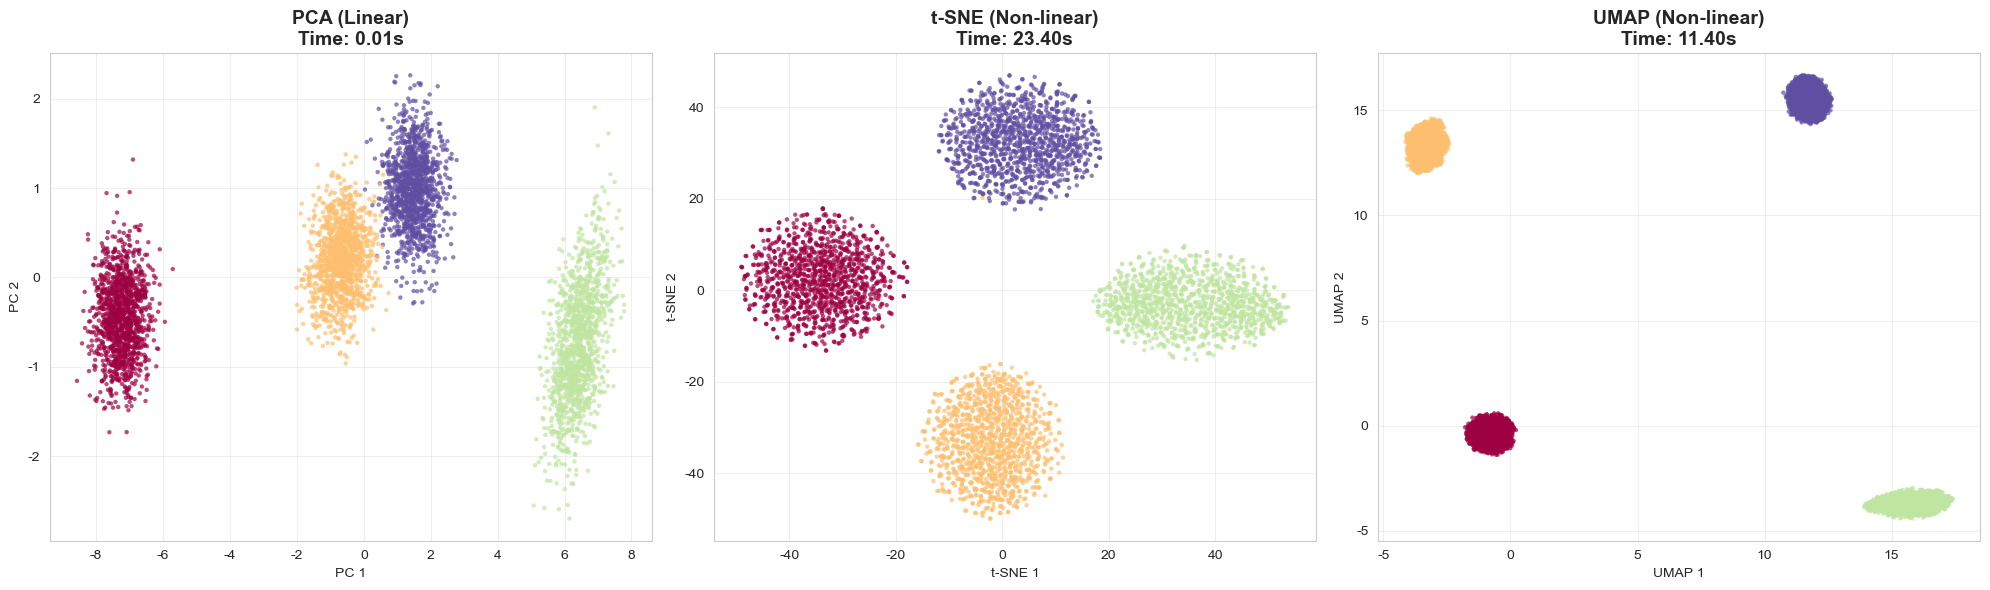

✓ 圖片已儲存至: d:\MyGit\ChemE-3590\Part_2\Unit06\outputs\P2_Unit06_UMAP\figs\comparison_pca_tsne_umap.png

計算時間比較:
  PCA:   0.01 秒
  t-SNE: 23.40 秒
  UMAP:  11.40 秒
  UMAP vs t-SNE: 2.1x 快


In [9]:
# 執行三種降維方法並比較

# 1. PCA
print("執行 PCA...")
start_time_pca = time.time()
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
time_pca = time.time() - start_time_pca

# 2. t-SNE
print("執行 t-SNE...")
start_time_tsne = time.time()
tsne = TSNE(n_components=2, perplexity=30, random_state=42, verbose=0)
X_tsne = tsne.fit_transform(X_scaled)
time_tsne = time.time() - start_time_tsne

# 3. UMAP
print("執行 UMAP...")
start_time_umap = time.time()
reducer_compare = umap.UMAP(n_neighbors=30, n_components=2, min_dist=0.1, random_state=42, verbose=False)
X_umap_compare = reducer_compare.fit_transform(X_scaled)
time_umap = time.time() - start_time_umap

# 視覺化比較
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# PCA
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], 
               c=y, cmap='Spectral', s=10, alpha=0.7, edgecolors='none')
axes[0].set_title(f'PCA (Linear)\nTime: {time_pca:.2f}s', fontsize=14, fontweight='bold')
axes[0].set_xlabel('PC 1')
axes[0].set_ylabel('PC 2')
axes[0].grid(True, alpha=0.3)

# t-SNE
axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], 
               c=y, cmap='Spectral', s=10, alpha=0.7, edgecolors='none')
axes[1].set_title(f't-SNE (Non-linear)\nTime: {time_tsne:.2f}s', fontsize=14, fontweight='bold')
axes[1].set_xlabel('t-SNE 1')
axes[1].set_ylabel('t-SNE 2')
axes[1].grid(True, alpha=0.3)

# UMAP
axes[2].scatter(X_umap_compare[:, 0], X_umap_compare[:, 1], 
               c=y, cmap='Spectral', s=10, alpha=0.7, edgecolors='none')
axes[2].set_title(f'UMAP (Non-linear)\nTime: {time_umap:.2f}s', fontsize=14, fontweight='bold')
axes[2].set_xlabel('UMAP 1')
axes[2].set_ylabel('UMAP 2')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / 'comparison_pca_tsne_umap.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ 圖片已儲存至:", FIG_DIR / 'comparison_pca_tsne_umap.png')
print(f"\n計算時間比較:")
print(f"  PCA:   {time_pca:.2f} 秒")
print(f"  t-SNE: {time_tsne:.2f} 秒")
print(f"  UMAP:  {time_umap:.2f} 秒")
print(f"  UMAP vs t-SNE: {time_tsne/time_umap:.1f}x 快")


---
## 6. 評估降維品質

### 6.1 信賴度 (Trustworthiness)

In [10]:
from sklearn.manifold import trustworthiness

# 計算不同 k 值的信賴度
k_values = [5, 10, 15, 30, 50]

print("信賴度 (Trustworthiness) 比較 [0-1, 越大越好]:\n")
print(f"{'k':<6} {'PCA':<10} {'t-SNE':<10} {'UMAP':<10}")
print("-" * 40)

for k in k_values:
    trust_pca = trustworthiness(X_scaled, X_pca, n_neighbors=k)
    trust_tsne = trustworthiness(X_scaled, X_tsne, n_neighbors=k)
    trust_umap = trustworthiness(X_scaled, X_umap_compare, n_neighbors=k)
    
    print(f"{k:<6} {trust_pca:<10.4f} {trust_tsne:<10.4f} {trust_umap:<10.4f}")

print("\n解讀:")
print("  > 0.9  : 極好，局部結構保持良好")
print("  0.8-0.9: 良好")
print("  0.7-0.8: 可接受")
print("  < 0.7  : 較差，需調整超參數")


信賴度 (Trustworthiness) 比較 [0-1, 越大越好]:

k      PCA        t-SNE      UMAP      
----------------------------------------
5      0.9026     0.9687     0.9123    
10     0.9032     0.9553     0.9127    
15     0.9038     0.9475     0.9129    
30     0.9059     0.9369     0.9143    
50     0.9086     0.9320     0.9164    

解讀:
  > 0.9  : 極好，局部結構保持良好
  0.8-0.9: 良好
  0.7-0.8: 可接受
  < 0.7  : 較差，需調整超參數


### 6.2 輪廓係數與 Davies-Bouldin 指數

In [11]:
# 計算群集分離度指標

# Silhouette Score (越大越好，範圍 [-1, 1])
sil_pca = silhouette_score(X_pca, y, metric='euclidean')
sil_tsne = silhouette_score(X_tsne, y, metric='euclidean')
sil_umap = silhouette_score(X_umap_compare, y, metric='euclidean')

# Davies-Bouldin Index (越小越好，範圍 [0, ∞))
db_pca = davies_bouldin_score(X_pca, y)
db_tsne = davies_bouldin_score(X_tsne, y)
db_umap = davies_bouldin_score(X_umap_compare, y)

# 彙整結果
results_df = pd.DataFrame({
    'Method': ['PCA', 't-SNE', 'UMAP'],
    'Silhouette Score (↑)': [sil_pca, sil_tsne, sil_umap],
    'Davies-Bouldin Index (↓)': [db_pca, db_tsne, db_umap],
    'Computation Time (s)': [time_pca, time_tsne, time_umap]
})

print("群集分離度評估:\n")
print(results_df.to_string(index=False))
print("\n解讀:")
print("  Silhouette Score: 接近 1 表示群集分離良好")
print("  Davies-Bouldin Index: 越小表示群集越緊密且分離")
print(f"\n結論: {results_df.loc[results_df['Silhouette Score (↑)'].idxmax(), 'Method']} 在群集分離度上表現最佳")

# 基準：原始 30 維標準化空間的指標（作為降維前的參考）
sil_orig = silhouette_score(X_scaled, y, metric='euclidean')
db_orig = davies_bouldin_score(X_scaled, y)
print(f"\n基準 (原始 30 維空間): Silhouette = {sil_orig:.4f}, Davies-Bouldin = {db_orig:.4f}")
print("註: 此類指標在各嵌入空間內計算，UMAP 會刻意壓縮群集，因此對 UMAP 有利；")
print("    它們反映群集緊密度，不代表鄰域保持較佳，請搭配 Trustworthiness 一併判讀")


群集分離度評估:

Method  Silhouette Score (↑)  Davies-Bouldin Index (↓)  Computation Time (s)
   PCA              0.761592                  0.326995              0.005003
 t-SNE              0.727285                  0.373662             23.401185
  UMAP              0.936143                  0.090773             11.401203

解讀:
  Silhouette Score: 接近 1 表示群集分離良好
  Davies-Bouldin Index: 越小表示群集越緊密且分離

結論: UMAP 在群集分離度上表現最佳

基準 (原始 30 維空間): Silhouette = 0.3754, Davies-Bouldin = 1.2183
註: 此類指標在各嵌入空間內計算，UMAP 會刻意壓縮群集，因此對 UMAP 有利；
    它們反映群集緊密度，不代表鄰域保持較佳，請搭配 Trustworthiness 一併判讀


---
## 7. 新數據投影 (UMAP Transform)

訓練集樣本數: 4000
測試集樣本數: 1000

✓ 訓練集 fit_transform 耗時: 28.40 秒 (4000 筆)
✓ 測試集 transform 耗時: 6.97 秒 (1000 筆，暖機後)
✓ 測試集投影後以 5-NN 還原操作模式的準確率: 1.0000


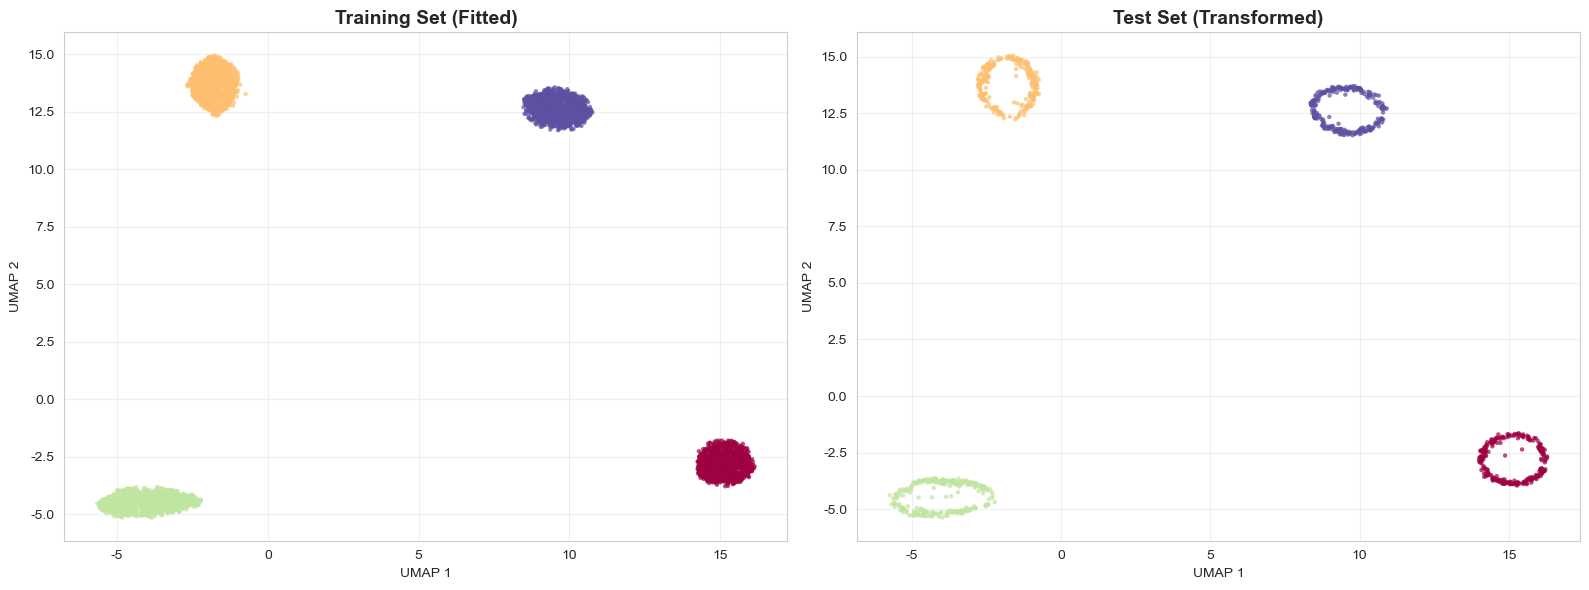

✓ 圖片已儲存至: d:\MyGit\ChemE-3590\Part_2\Unit06\outputs\P2_Unit06_UMAP\figs\umap_new_data_projection.png

註: transform 投影的新點可能沿群集外緣分佈（環狀假象），群集歸屬可信，但不可用點的疏密解讀密度


In [12]:
# UMAP 支援新數據投影（t-SNE 不支援）
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
import joblib

# 先分割原始數據，再僅以訓練集擬合 Scaler（避免資料洩漏）
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
scaler_tt = StandardScaler()
X_train = scaler_tt.fit_transform(X_train_raw)
X_test = scaler_tt.transform(X_test_raw)

print(f"訓練集樣本數: {len(X_train)}")
print(f"測試集樣本數: {len(X_test)}")

# 在訓練集上訓練 UMAP
start_fit = time.time()
reducer_transform = umap.UMAP(
    n_neighbors=30,
    n_components=2,
    min_dist=0.1,
    random_state=SEED,
    verbose=False
)
X_train_umap = reducer_transform.fit_transform(X_train)
time_fit_train = time.time() - start_fit

# 暖機：第一次呼叫 transform 會包含 numba JIT 編譯時間，先以少量樣本執行
_ = reducer_transform.transform(X_test[:10])

# 投影測試集（不需重新擬合整個模型）
start_transform = time.time()
X_test_umap = reducer_transform.transform(X_test)
time_transform = time.time() - start_transform

print(f"\n✓ 訓練集 fit_transform 耗時: {time_fit_train:.2f} 秒 ({len(X_train)} 筆)")
print(f"✓ 測試集 transform 耗時: {time_transform:.2f} 秒 ({len(X_test)} 筆，暖機後)")

# 定量驗證：以訓練集嵌入座標訓練 5-NN，檢查測試集投影點能否還原操作模式
knn = KNeighborsClassifier(n_neighbors=5).fit(X_train_umap, y_train)
acc_test = knn.score(X_test_umap, y_test)
print(f"✓ 測試集投影後以 5-NN 還原操作模式的準確率: {acc_test:.4f}")

# 視覺化
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 訓練集
axes[0].scatter(X_train_umap[:, 0], X_train_umap[:, 1],
               c=y_train, cmap='Spectral', s=10, alpha=0.7, edgecolors='none')
axes[0].set_title('Training Set (Fitted)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('UMAP 1')
axes[0].set_ylabel('UMAP 2')
axes[0].grid(True, alpha=0.3)

# 測試集
axes[1].scatter(X_test_umap[:, 0], X_test_umap[:, 1],
               c=y_test, cmap='Spectral', s=10, alpha=0.7, edgecolors='none')
axes[1].set_title('Test Set (Transformed)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('UMAP 1')
axes[1].set_ylabel('UMAP 2')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / 'umap_new_data_projection.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ 圖片已儲存至:", FIG_DIR / 'umap_new_data_projection.png')
print("\n註: transform 投影的新點可能沿群集外緣分佈（環狀假象），群集歸屬可信，但不可用點的疏密解讀密度")


### 7.1 儲存與載入模型

實際部署時需同時保存 `Scaler` 與 `UMAP` 模型，確保新數據以相同方式前處理與投影。

In [13]:
# 儲存 Scaler 與 UMAP 模型
joblib.dump(scaler_tt, MODEL_DIR / 'scaler.pkl')
joblib.dump(reducer_transform, MODEL_DIR / 'umap_reducer.pkl')
print("✓ 模型已儲存:")
print("  -", MODEL_DIR / 'scaler.pkl')
print("  -", MODEL_DIR / 'umap_reducer.pkl')

# 載入模型並驗證投影結果與原模型一致
scaler_loaded = joblib.load(MODEL_DIR / 'scaler.pkl')
reducer_loaded = joblib.load(MODEL_DIR / 'umap_reducer.pkl')
X_test_loaded = reducer_loaded.transform(scaler_loaded.transform(X_test_raw))
max_diff = np.abs(X_test_loaded - X_test_umap).max()
print(f"\n✓ 載入模型後的投影結果與原模型最大差異: {max_diff:.2e}")


✓ 模型已儲存:
  - d:\MyGit\ChemE-3590\Part_2\Unit06\outputs\P2_Unit06_UMAP\models\scaler.pkl
  - d:\MyGit\ChemE-3590\Part_2\Unit06\outputs\P2_Unit06_UMAP\models\umap_reducer.pkl

✓ 載入模型後的投影結果與原模型最大差異: 0.00e+00


---
## 8. 總結與建議

### 核心要點回顧

本 Notebook 完整演示了 UMAP (Uniform Manifold Approximation and Projection) 在化工製程數據降維與視覺化的應用。

#### 1. UMAP 的核心優勢
- **速度快**: 在大規模數據上可比 t-SNE 快數倍至數十倍（本實驗 5000 樣本約快 2 倍）
- **全局結構**: 在保留局部群集的同時，也保留更多全局信息（但群集間的相對位置與距離仍不可過度解讀）
- **新數據投影**: 支援 `transform()` 方法，t-SNE 無法投影新數據（新點可能呈環狀分佈，群集歸屬可信但不可解讀密度）
- **超參數直觀**: `n_neighbors` 控制局部-全局平衡，`min_dist` 控制點的緊密程度

#### 2. 關鍵超參數選擇
- **製程監控**: `n_neighbors=50-100`, `min_dist=0.1` (保留全局結構)
- **故障診斷**: `n_neighbors=10-20`, `min_dist=0.0` (強調局部異常)
- **批次軌跡分析**: `n_neighbors=30-50`, `min_dist=0.3-0.5` (保留連續性)

#### 3. 與其他方法的比較
| 方法 | 速度 | 全局結構 | 局部結構 | 新數據投影 | 適用場景 |
|------|------|---------|---------|-----------|---------|
| **PCA** | 極快 | 好 | 中等 | 支援 | 線性降維、快速探索 |
| **t-SNE** | 慢 | 差 | 極好 | 不支援 | 小規模、純視覺化 |
| **UMAP** | 快 | 較好 | 好 | 支援 | 大規模、實時應用 |

#### 4. 化工應用建議
- **大規模製程數據視覺化**: 首選 UMAP，速度快且效果好
- **操作模式識別**: UMAP + 分群 (K-Means/DBSCAN)
- **批次製程軌跡分析**: UMAP (較大 `min_dist` 保留連續性)
- **實時監控**: UMAP (支援新數據投影)
- **學術報告視覺化**: UMAP 或 t-SNE (視覺化品質高)

#### 5. 評估指標
- **信賴度 (Trustworthiness)**: > 0.9 表示局部結構保持良好
- **輪廓係數 (Silhouette Score)**: 接近 1 表示群集分離良好
- **Davies-Bouldin Index**: 越小表示群集越緊密
- **注意**: 輪廓係數與 DB 指數在嵌入空間計算，會偏袒壓縮群集的 UMAP，應搭配 Trustworthiness 與原始空間基準判讀

#### 6. 下一步
- 完成 **Unit06_Dimensionality_Reduction_Homework.ipynb** 作業
- 將 UMAP 應用於實際製程數據
- 嘗試不同超參數組合，觀察效果
- 結合分群與異常檢測進行製程監控

---

**課程完成！恭喜您掌握 UMAP 降維技術！** 🎉
